# 02 · Treino (fine-tuning YOLO)

- **Arquitetura:** YOLO11n (Ultralytics), detector de um estágio: backbone CNN extrai características,
  neck (FPN/PAN) combina escalas e a head prevê caixa + confiança diretamente, sem etapa de propostas → rápido o bastante para vídeo.
- **Transferência de aprendizado:** parte de pesos pré-treinados no COCO e aprende a classe nova `buraco`.
- **Hiperparâmetros:** 100 épocas (early stopping com paciência 25), imagem 640 px, lote 16, otimizador automático,
  aumentos: brilho (hsv_v 0.4), rotação ±5°, escala 0.5, espelhamento horizontal, mosaico.
- **Hardware de referência:** RTX 5060 Ti 8 GB, 16 GB de RAM (4 *workers* de carregamento de imagens).

O treino foi executado uma vez pelo terminal, com o comando abaixo; este notebook **não retreina** — ele lê os
resultados gravados em `runs/buraco_yolo11n/` e em `modelos/treino.json`.

```bash
python scripts/treinar.py --modelo yolo11n.pt --epocas 100 --lote 16
```

In [1]:
import torch; print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

2.11.0+cu128 True NVIDIA GeForce RTX 5060 Ti


In [2]:
import json
from pathlib import Path
import pandas as pd

run = Path("../runs/buraco_yolo11n")
print("Configuração usada:", json.loads(Path("../modelos/treino.json").read_text(encoding="utf-8")))
r = pd.read_csv(run / "results.csv"); r.columns = r.columns.str.strip()
melhor = r.loc[r["metrics/mAP50-95(B)"].idxmax()]  # o Ultralytics guarda como best.pt a época de maior mAP50-95 na validação
print(f"Épocas executadas: {len(r)} de 100 (parada antecipada, paciência 25)")
print(f"Melhor época: {int(melhor.epoch)} · validação: mAP50 {melhor['metrics/mAP50(B)']:.3f} · "
      f"mAP50-95 {melhor['metrics/mAP50-95(B)']:.3f} · precisão {melhor['metrics/precision(B)']:.3f} · "
      f"recall {melhor['metrics/recall(B)']:.3f}")
print(f"Tempo de treino: {r.time.iloc[-1] / 60:.1f} min")

Configuração usada: {'dados': 'dados/zelacidade/zelacidade.yaml', 'modelo': 'yolo11n.pt', 'epocas': 100, 'imgsz': 640, 'lote': 16, 'workers': 4, 'nome': 'buraco_yolo11n'}
Épocas executadas: 95 de 100 (parada antecipada, paciência 25)
Melhor época: 70 · validação: mAP50 0.784 · mAP50-95 0.481 · precisão 0.791 · recall 0.722
Tempo de treino: 6.4 min


## Curvas de treino

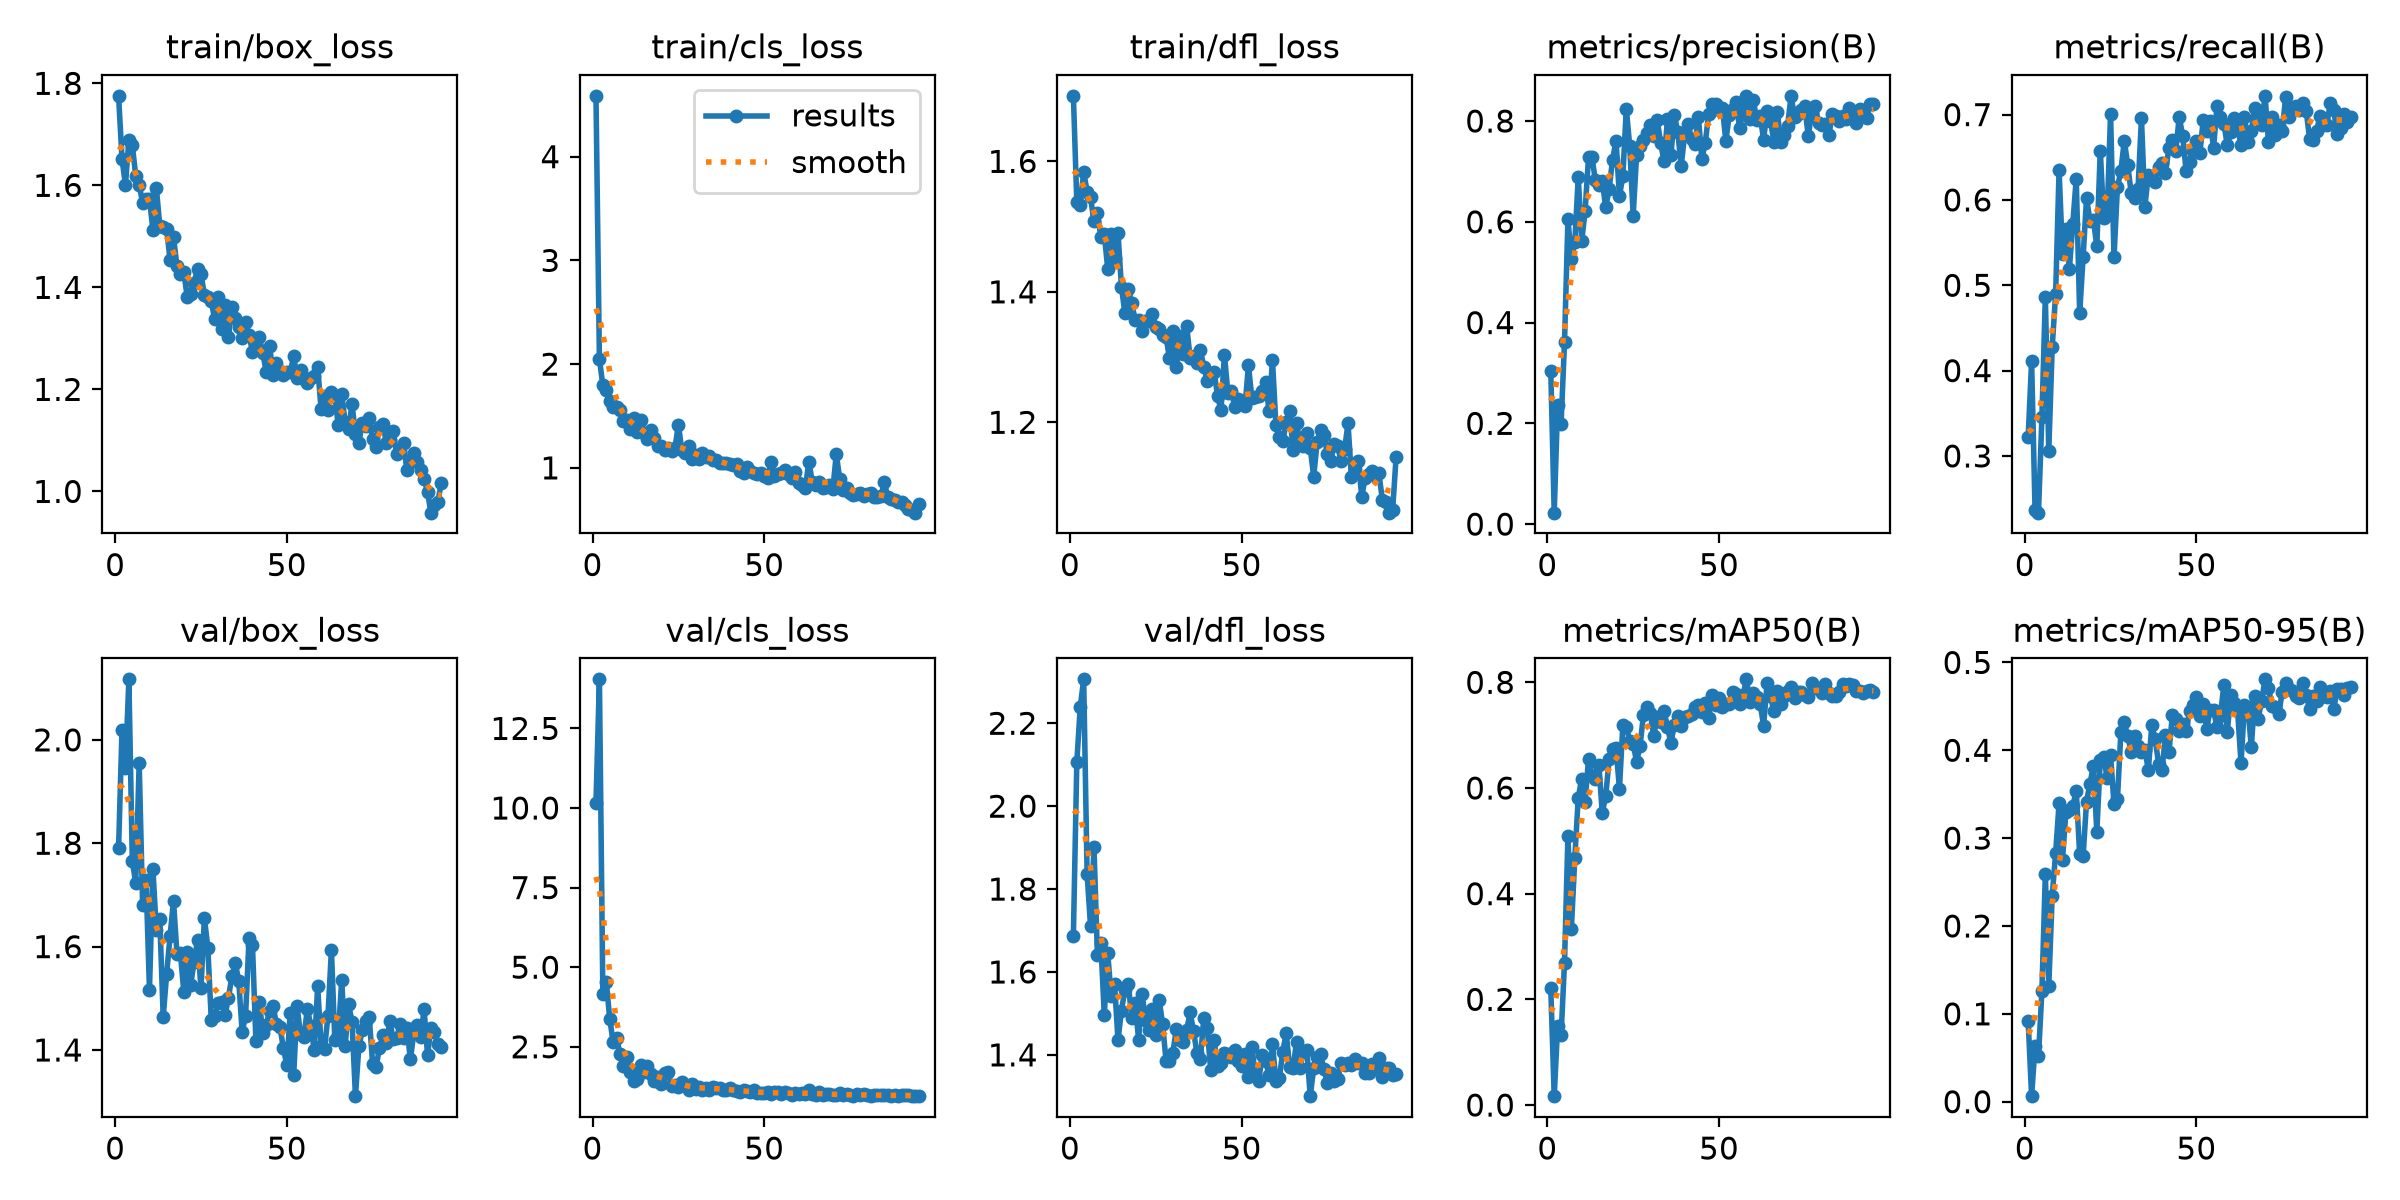

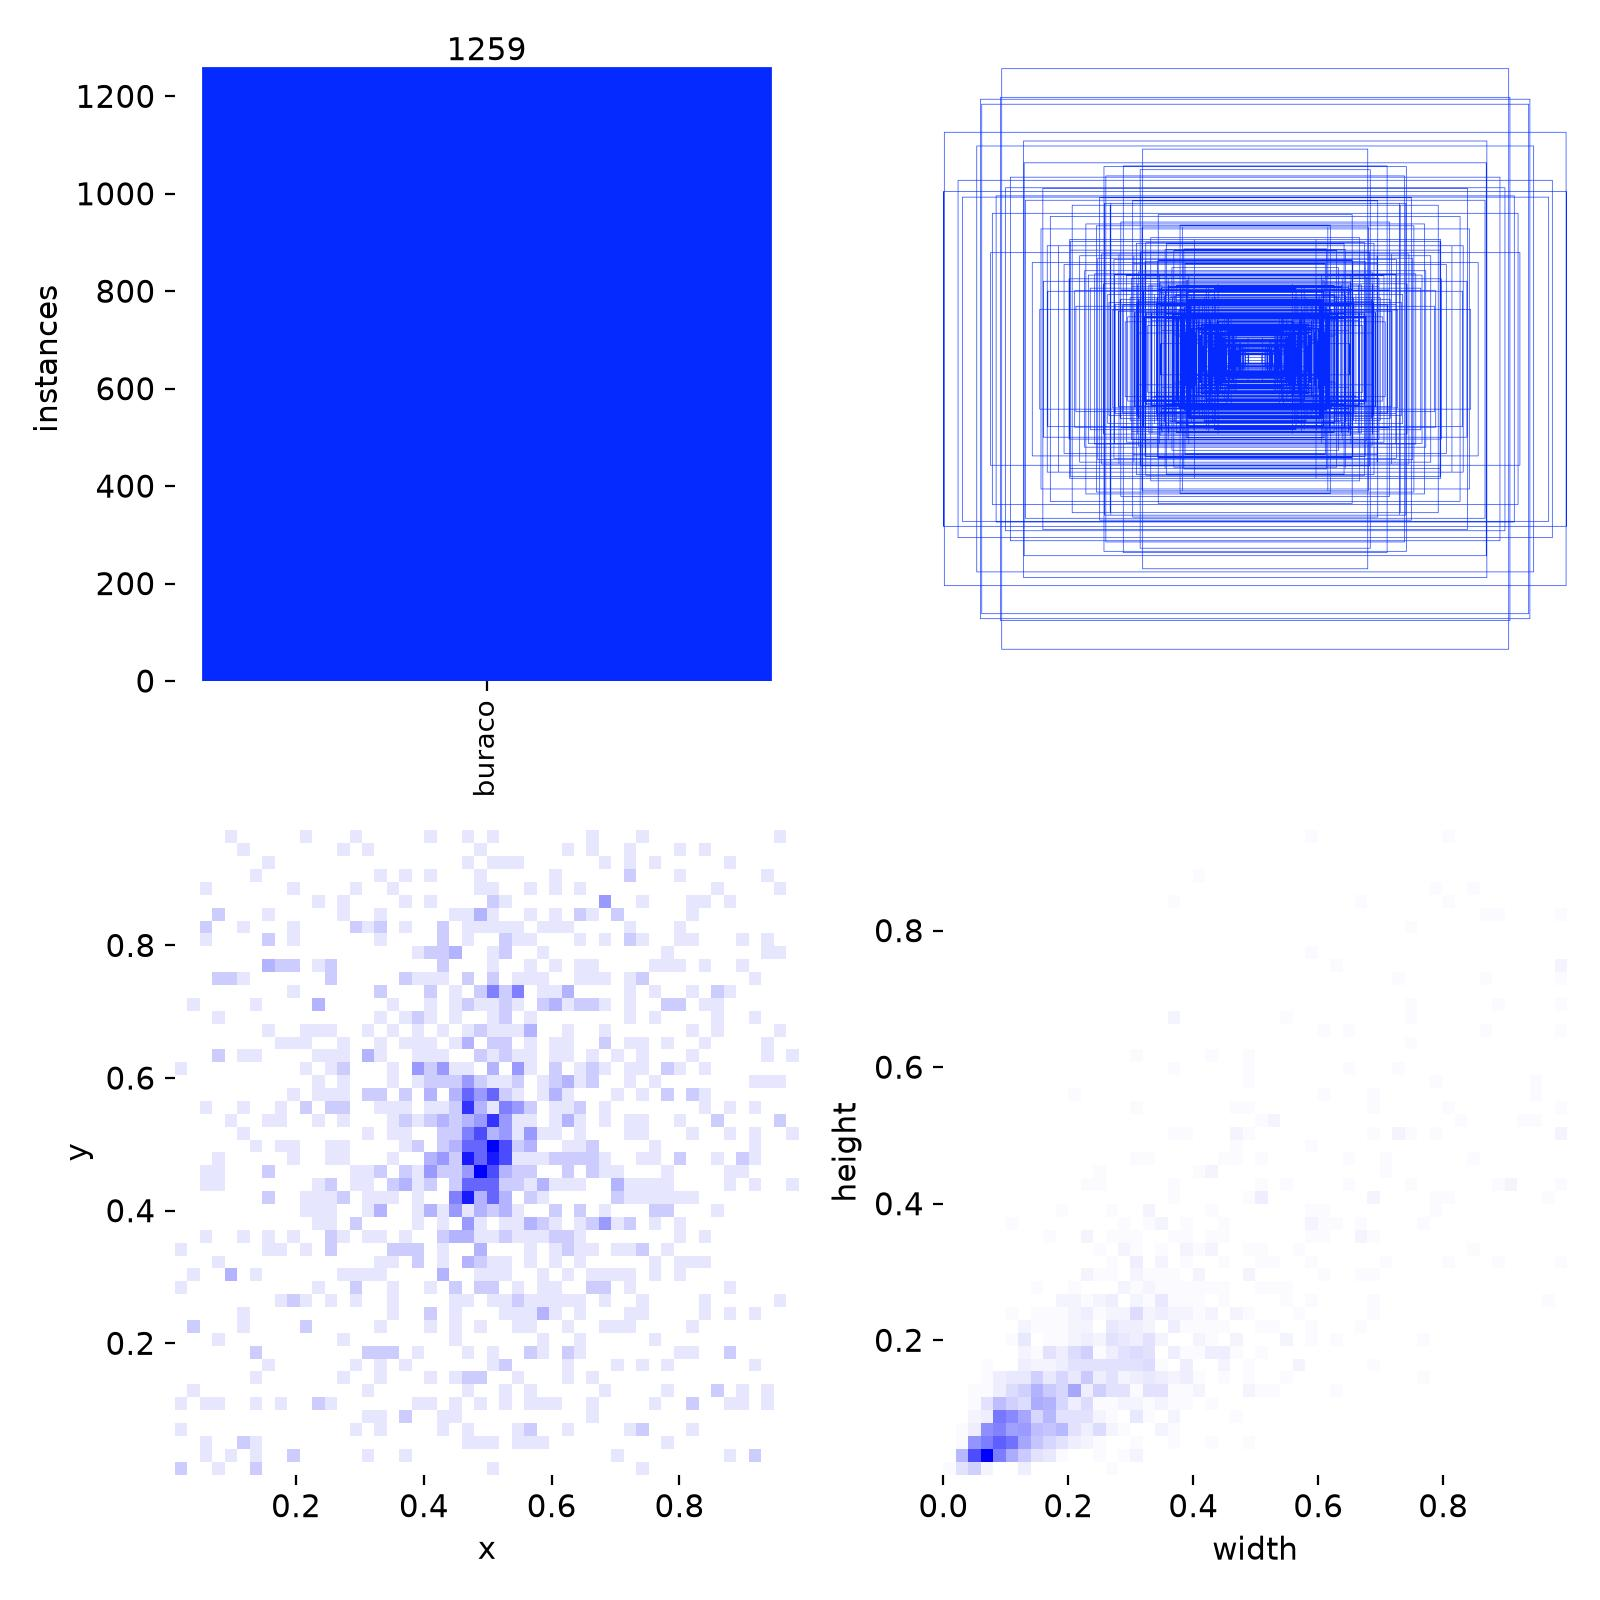

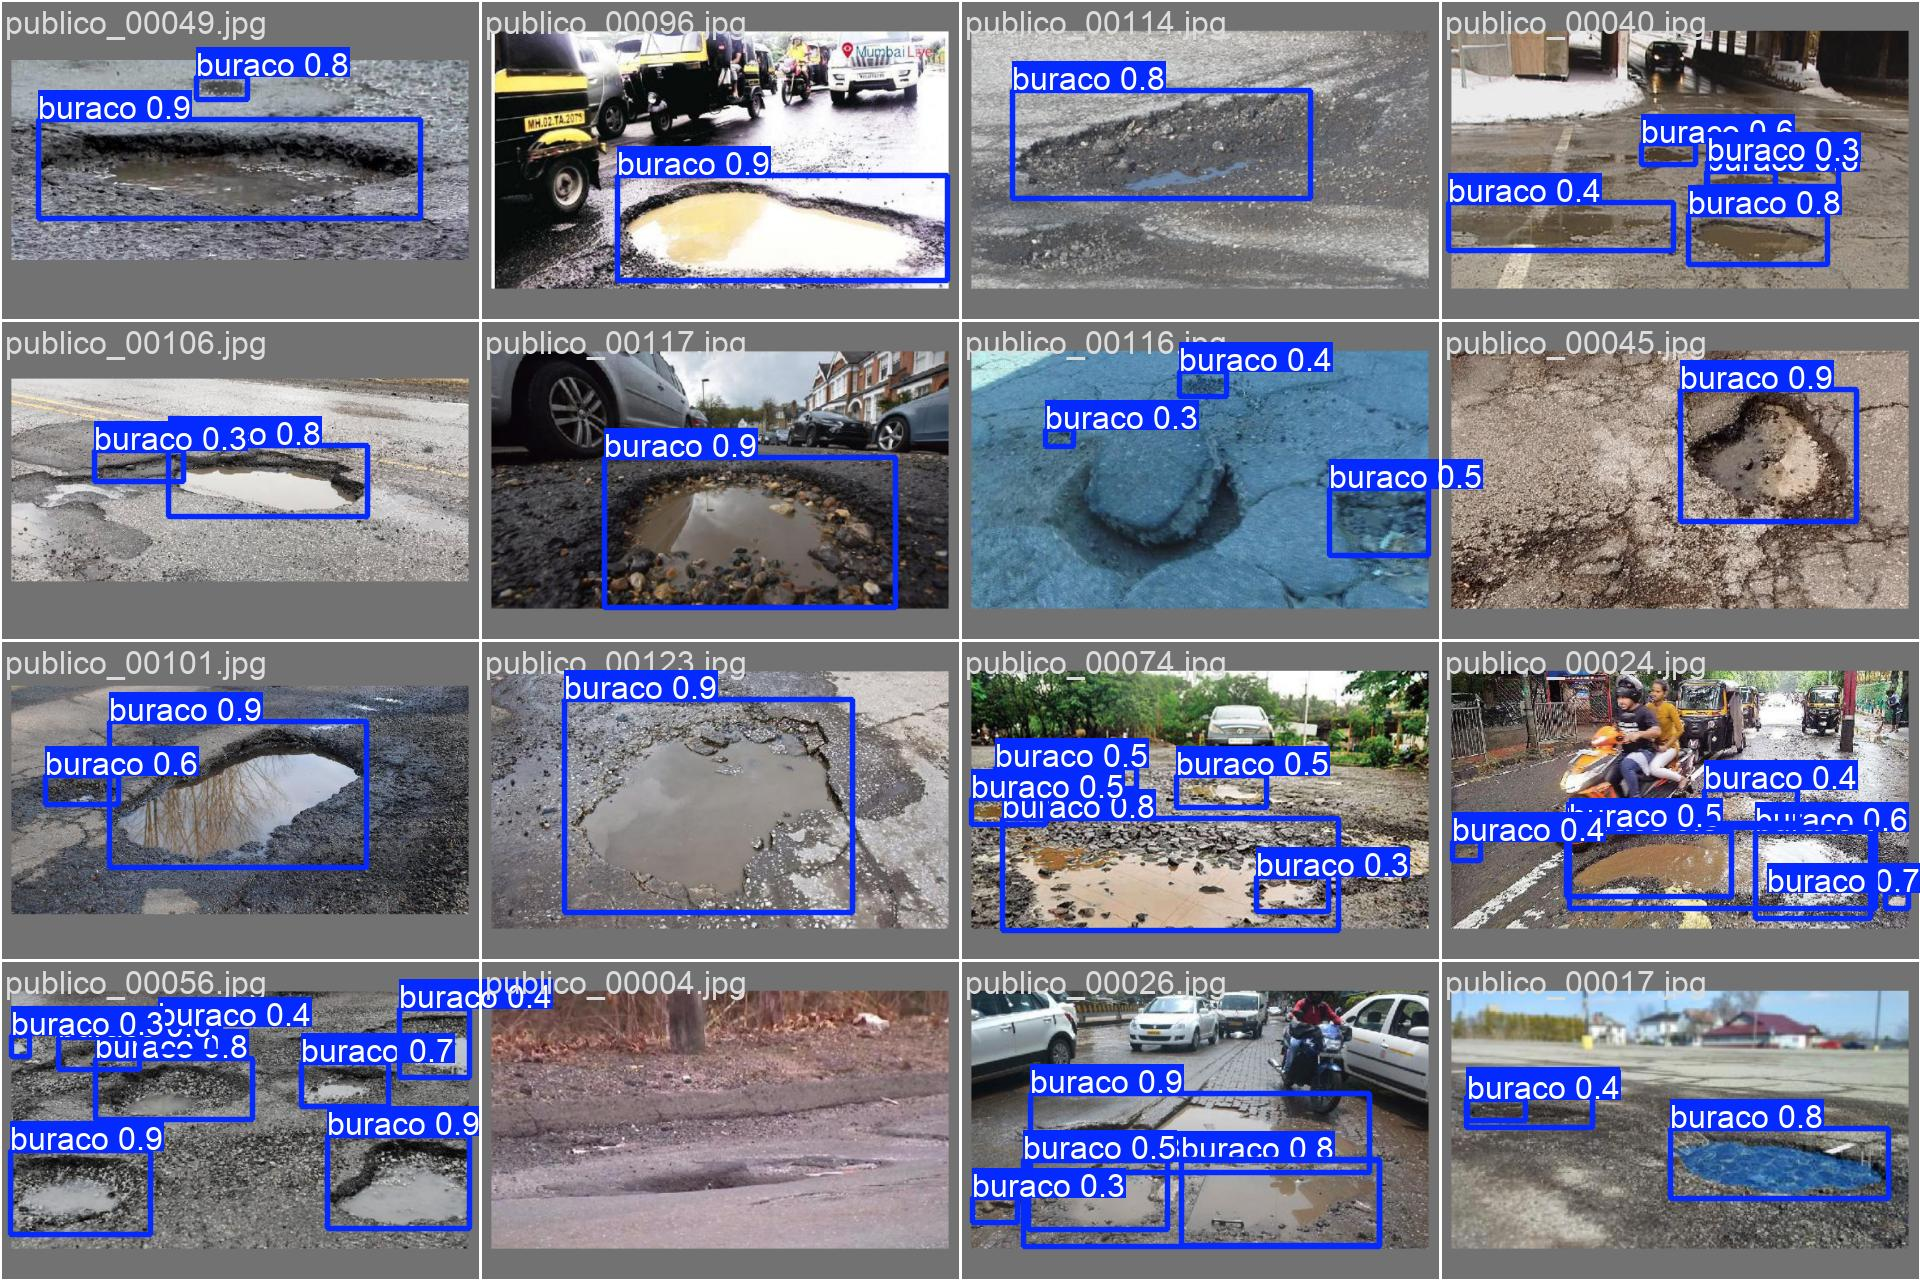

In [3]:
from IPython.display import Image, display
for f in ["results.png", "labels.jpg", "val_batch0_pred.jpg"]:
    if (run / f).exists():
        display(Image(str(run / f), width=900))

In [4]:
import pandas as pd
r = pd.read_csv(run / "results.csv"); r.columns = r.columns.str.strip()
r[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].tail(10)

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
85,86,0.80926,0.69783,0.79698,0.47154
86,87,0.80445,0.68750,0.79361,0.46175
87,88,0.82511,0.68750,0.79720,0.46070
88,89,0.81754,0.71382,0.79518,0.46714
89,90,0.79586,0.70535,0.78411,0.44680
90,91,0.82396,0.67763,0.78289,0.46927
91,92,0.82017,0.68421,0.78060,0.47003
92,93,0.80505,0.70066,0.78330,0.46294
93,94,0.83348,0.69151,0.78631,0.47078
94,95,0.83359,0.69737,0.78178,0.47235
